# Data quality gate (conditional workflow)

An incoming batch is profiled, then routed:
- **clean** (null % < 5) -> load to warehouse
- **minor issues** (5 <= null % < 30) -> clean the data, then load
- **critical** (null % >= 30) -> quarantine and alert

In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [2]:
class PipelineState(TypedDict):

    rows: list[dict]
    null_percent: float
    status: str

In [3]:
def profile_data(state: PipelineState):

    rows = state['rows']
    total_cells = sum(len(r) for r in rows)
    null_cells = sum(1 for r in rows for v in r.values() if v is None)
    null_percent = (null_cells / total_cells) * 100 if total_cells else 100.0

    return {'null_percent': null_percent}


def clean_data(state: PipelineState):

    # drop rows that contain any null
    cleaned = [r for r in state['rows'] if None not in r.values()]

    return {'rows': cleaned}


def load_to_warehouse(state: PipelineState):

    return {'status': f"Loaded {len(state['rows'])} rows to warehouse"}


def quarantine_and_alert(state: PipelineState):

    return {'status': f"Batch quarantined, alert sent ({state['null_percent']:.1f}% nulls)"}


# routing function: returns the name of the next node
def route_by_quality(state: PipelineState) -> Literal['load_to_warehouse', 'clean_data', 'quarantine_and_alert']:

    if state['null_percent'] < 5:
        return 'load_to_warehouse'
    elif state['null_percent'] < 30:
        return 'clean_data'
    else:
        return 'quarantine_and_alert'

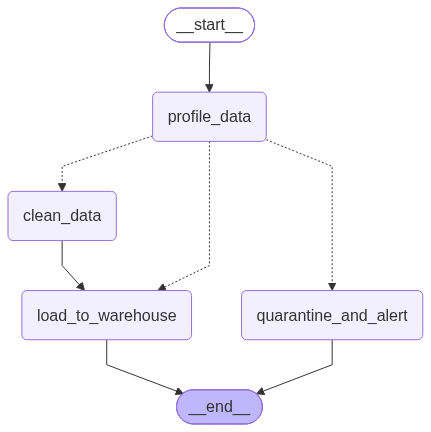

In [4]:
graph = StateGraph(PipelineState)

graph.add_node('profile_data', profile_data)
graph.add_node('clean_data', clean_data)
graph.add_node('load_to_warehouse', load_to_warehouse)
graph.add_node('quarantine_and_alert', quarantine_and_alert)

graph.add_edge(START, 'profile_data')
graph.add_conditional_edges('profile_data', route_by_quality)

graph.add_edge('clean_data', 'load_to_warehouse')
graph.add_edge('load_to_warehouse', END)
graph.add_edge('quarantine_and_alert', END)

workflow = graph.compile()
workflow

In [5]:
good_batch = [{'id': i, 'amount': i * 10, 'city': 'NYC'} for i in range(1, 41)]

# 1 null in 40 rows * 3 cols = 120 cells -> ~0.8%
good_batch[0]['city'] = None

# 7 more nulls (8 total of 120 cells) -> ~6.7%
minor_batch = [dict(r) for r in good_batch]
for i in range(7):
    minor_batch[i]['amount'] = None

# 20 rows fully nulled (60 of 120 cells) -> 50%
bad_batch = [dict(r) for r in good_batch]
for i in range(20):
    bad_batch[i]['amount'] = None
    bad_batch[i]['city'] = None
    bad_batch[i]['id'] = None

for name, batch in [('good', good_batch), ('minor', minor_batch), ('bad', bad_batch)]:
    result = workflow.invoke({'rows': batch})
    print(name, '->', round(result['null_percent'], 1), '%', '|', result['status'])

good -> 0.8 % | Loaded 40 rows to warehouse
minor -> 6.7 % | Loaded 33 rows to warehouse
bad -> 50.0 % | Batch quarantined, alert sent (50.0% nulls)
